# Notebook 03 — Parametric VaR

Parametric VaR estimates portfolio risk by assuming that daily portfolio returns follow a normal distribution.

Instead of using historical percentiles, the portfolio's expected return and volatility are used to calculate Value at Risk analytically. Expected Shortfall (ES) is also estimated under the same assumption.

The results are then compared with Historical Simulation VaR to illustrate the differences between a distribution-based approach and one that relies directly on historical market data.

## Outputs

- Parametric VaR (95%, 99%)
- Expected Shortfall
- Comparison with Historical VaR


Portfolio Mean       : 0.0508%
Portfolio Volatility : 1.2496%

Portfolio Covariance Matrix
       AAPL     GS    JNJ    JPM    XOM
AAPL 0.0003 0.0002 0.0001 0.0001 0.0001
GS   0.0002 0.0003 0.0001 0.0003 0.0002
JNJ  0.0001 0.0001 0.0001 0.0001 0.0001
JPM  0.0001 0.0003 0.0001 0.0003 0.0002
XOM  0.0001 0.0002 0.0001 0.0002 0.0003

Parametric VaR
--------------------------------------------------

95% Confidence
  z-score : -1.6449
  VaR     : 2.0046% ($20,046)
  ES      : 2.5267% ($25,267)

99% Confidence
  z-score : -2.3263
  VaR     : 2.8562% ($28,562)
  ES      : 3.2796% ($32,796)
--------------------------------------------------

Model Comparison
----------------------------------------
Model                 95%       99%
----------------------------------------
Parametric        2.0046%   2.8562%
Historical        1.8045%   3.4161%
----------------------------------------


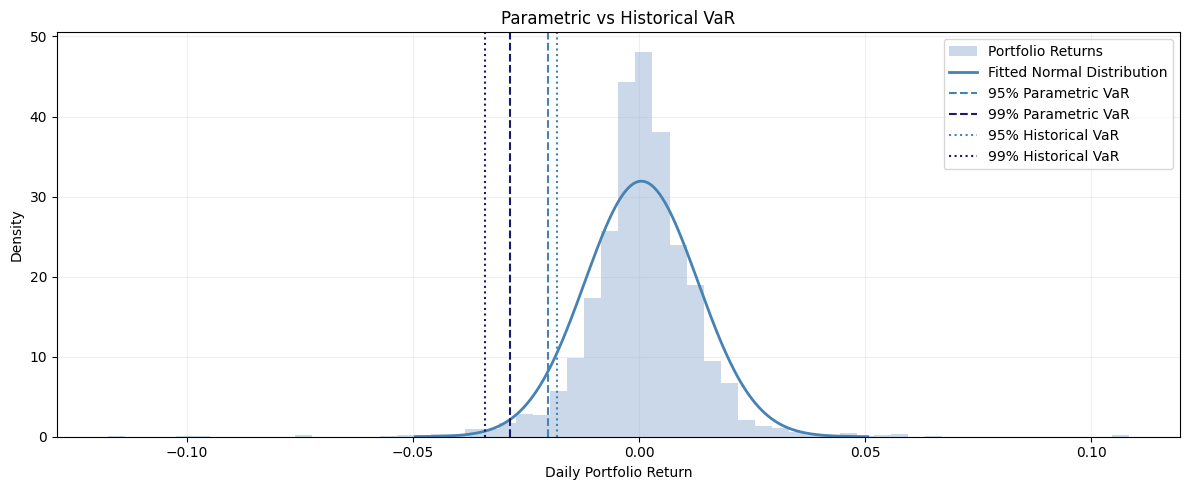

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]
portfolio_value = 1_000_000

# Load Data

log_returns = pd.read_csv("../data/log_returns.csv",index_col=0, parse_dates=True)
assert log_returns.isna().sum().sum() == 0

#Portfolio Parameters 

mu = log_returns.mean()
cov_matrix = log_returns.cov()
mu_p = weights @ mu
sigma_p = np.sqrt(weights @ cov_matrix @ weights)

print(f"Portfolio Mean       : {mu_p*100:.4f}%")
print(f"Portfolio Volatility : {sigma_p*100:.4f}%")

print("\nPortfolio Covariance Matrix")
print(cov_matrix.round(6))

# Parametric VaR

param_results = {}

print("\nParametric VaR")
print("-" * 50)

for cl in confidence_levels:
    z = norm.ppf(1 - cl)
    var_pct = -(mu_p + z * sigma_p)
    # Parametric Expected Shortfall
    es_pct = (-mu_p + sigma_p * norm.pdf(z) / (1 - cl))

    var_dollar = var_pct * portfolio_value
    es_dollar = es_pct * portfolio_value

    param_results[cl] = {
        "var_pct": var_pct,
        "es_pct": es_pct,
        "var_dollar": var_dollar,
        "es_dollar": es_dollar}

    print(f"\n{cl*100:.0f}% Confidence")
    print(f"  z-score : {z:.4f}")
    print(f"  VaR     : {var_pct*100:.4f}% (${var_dollar:,.0f})")
    print(f"  ES      : {es_pct*100:.4f}% (${es_dollar:,.0f})")

print("-" * 50)

# Comparison with Historical VaR 

simple_returns = np.exp(log_returns) - 1
portfolio_simple_returns = simple_returns.dot(weights)
portfolio_returns = np.log1p(portfolio_simple_returns)

p_var_95 = param_results[0.95]["var_pct"]
p_var_99 = param_results[0.99]["var_pct"]

h_var_95 = -np.percentile(portfolio_returns, 5)
h_var_99 = -np.percentile(portfolio_returns, 1)

print("\nModel Comparison")
print("-" * 40)
print(f"{'Model':<15}{'95%':>10}{'99%':>10}")
print("-" * 40)
print(f"{'Parametric':<15}{p_var_95*100:>9.4f}%{p_var_99*100:>9.4f}%")
print(f"{'Historical':<15}{h_var_95*100:>9.4f}%{h_var_99*100:>9.4f}%")
print("-" * 40)

#Visualization
fig, ax = plt.subplots(figsize=(12, 5))

# Range for fitted normal distribution
x = np.linspace(
    portfolio_returns.mean() - 4 * portfolio_returns.std(),
    portfolio_returns.mean() + 4 * portfolio_returns.std(), 300)

# Historical portfolio return distribution
ax.hist(
    portfolio_returns,
    bins=60,
    density=True,
    color="lightsteelblue",
    alpha=0.65,
    label="Portfolio Returns")

# Fitted normal distribution
ax.plot(
    x,
    norm.pdf(x, mu_p, sigma_p),
    color="steelblue",
    linewidth=2,
    label="Fitted Normal Distribution")

# Parametric VaR
ax.axvline(
    -p_var_95,
    color="steelblue",
    linestyle="--",
    linewidth=1.5,
    label="95% Parametric VaR")

ax.axvline(
    -p_var_99,
    color="midnightblue",
    linestyle="--",
    linewidth=1.5,
    label="99% Parametric VaR")

# Historical VaR
ax.axvline(
    -h_var_95,
    color="steelblue",
    linestyle=":",
    linewidth=1.5,
    label="95% Historical VaR")

ax.axvline(
    -h_var_99,
    color="midnightblue",
    linestyle=":",
    linewidth=1.5,
    label="99% Historical VaR")


ax.set_title("Parametric vs Historical VaR")
ax.set_xlabel("Daily Portfolio Return")
ax.set_ylabel("Density")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

os.makedirs("../reports", exist_ok=True)
plt.savefig("../reports/03_parametric_var.png",dpi=150)
plt.show()